In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/car_details_v3.csv")
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [2]:
print("Shape:", df.shape)
print()
df.info()
print()
print("Missing values per column:")
print(df.isnull().sum())
print()
print("Duplicate rows:", df.duplicated().sum())


Shape: (8128, 13)

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB

Missing values per column:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmissio

In [3]:
# 1. Do the same rows miss mileage, engine and seats?
missing_rows = df[df["mileage"].isnull()]
print("Rows with missing mileage:", len(missing_rows))
print("...of which engine is also missing:", missing_rows["engine"].isnull().sum())
print("...of which seats is also missing:", missing_rows["seats"].isnull().sum())
print()

# 2. Look at a few of those rows
print(missing_rows.head())
print()

# 3. Look at some duplicated rows
dups = df[df.duplicated(keep=False)]
print(dups.sort_values(by=["name", "year", "km_driven"]).head(10))

Rows with missing mileage: 221
...of which engine is also missing: 221
...of which seats is also missing: 221

                            name  year  selling_price  km_driven    fuel  \
13          Maruti Swift 1.3 VXi  2007         200000      80000  Petrol   
31            Fiat Palio 1.2 ELX  2003          70000      50000  Petrol   
78               Tata Indica DLS  2003          50000      70000  Diesel   
87   Maruti Swift VDI BSIV W ABS  2015         475000      78000  Diesel   
119        Maruti Swift VDI BSIV  2010         300000     120000  Diesel   

    seller_type transmission         owner mileage engine max_power torque  \
13   Individual       Manual  Second Owner     NaN    NaN       NaN    NaN   
31   Individual       Manual  Second Owner     NaN    NaN       NaN    NaN   
78   Individual       Manual   First Owner     NaN    NaN       NaN    NaN   
87       Dealer       Manual   First Owner     NaN    NaN       NaN    NaN   
119  Individual       Manual  Second Owner

In [4]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

print(df.loc[[1857, 3236, 5245, 7699]])

                            name  year  selling_price  km_driven    fuel seller_type transmission        owner     mileage   engine max_power               torque  seats
1857  Audi Q5 35TDI Premium Plus  2018        3975000      31800  Diesel      Dealer    Automatic  First Owner  17.01 kmpl  1968 CC   188 bhp  400nm@ 1750-3000rpm    5.0
3236  Audi Q5 35TDI Premium Plus  2018        3975000      31800  Diesel      Dealer    Automatic  First Owner  17.01 kmpl  1968 CC   188 bhp  400nm@ 1750-3000rpm    5.0
5245  Audi Q5 35TDI Premium Plus  2018        3975000      31800  Diesel      Dealer    Automatic  First Owner  17.01 kmpl  1968 CC   188 bhp  400nm@ 1750-3000rpm    5.0
7699  Audi Q5 35TDI Premium Plus  2018        3975000      31800  Diesel      Dealer    Automatic  First Owner  17.01 kmpl  1968 CC   188 bhp  400nm@ 1750-3000rpm    5.0


In [6]:
print("Before:", df.shape)
df = df.drop_duplicates().reset_index(drop=True)
print("After:", df.shape)
print("Duplicates left:", df.duplicated().sum())

Before: (6926, 13)
After: (6926, 13)
Duplicates left: 0


In [7]:
print("Missing values after removing duplicates:")
print(df.isnull().sum())
print()

for col in ["mileage", "engine", "max_power"]:
    print(col)
    print(df[col].str.split().str[-1].value_counts(dropna=False))
    print()

Missing values after removing duplicates:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

mileage
mileage
kmpl     6631
NaN       208
km/kg      87
Name: count, dtype: int64

engine
engine
CC     6718
NaN     208
Name: count, dtype: int64

max_power
max_power
bhp    6718
NaN     205
0         3
Name: count, dtype: int64



In [8]:
# 1. Engine units (the part that was hidden)
print(df["engine"].str.split().str[-1].value_counts(dropna=False))
print()

# 2. Which fuel types have mileage in km/kg?
km_kg = df[df["mileage"].str.endswith("km/kg", na=False)]
print(km_kg["fuel"].value_counts())
print()

# 3. The rows where max_power has no unit
print(df[df["max_power"].str.split().str[-1] == "0"])


engine
CC     6718
NaN     208
Name: count, dtype: int64

fuel
CNG    52
LPG    35
Name: count, dtype: int64

                                 name  year  selling_price  km_driven    fuel seller_type transmission        owner mileage engine max_power torque  seats
547               Maruti Alto K10 LXI  2011         204999      97500  Petrol  Individual       Manual  First Owner     NaN    NaN         0    NaN    NaN
1309  Maruti Swift Dzire VDI Optional  2017         589000      41232  Diesel      Dealer       Manual  First Owner     NaN    NaN         0    NaN    NaN
2352   Tata Indica Vista Quadrajet LS  2012         240000      70000  Diesel  Individual       Manual  First Owner     NaN    NaN         0    NaN    NaN


In [9]:
# Treat 0 power as missing
df["max_power"] = df["max_power"].replace("0", np.nan)

# Convert text columns to numbers
df["mileage"] = df["mileage"].str.split().str[0].astype(float)
df["engine"] = df["engine"].str.split().str[0].astype(float)
df["max_power"] = df["max_power"].str.split().str[0].astype(float)

df[["mileage", "engine", "max_power", "seats"]].info()
print(df[["mileage", "engine", "max_power", "seats"]].describe())

ValueError: could not convert string to float: 'bhp'

In [10]:
bad = df[df["max_power"].notnull() & ~df["max_power"].str.split().str[0].str.replace(".", "", regex=False).str.isdigit()]
print(len(bad))
print(bad["max_power"].value_counts())

TypeError: bad operand type for unary ~: 'float'

In [11]:
first_piece = df["max_power"].str.split().str[0]
converted = pd.to_numeric(first_piece, errors="coerce")

bad = df[df["max_power"].notnull() & converted.isnull()]
print("Problem rows:", len(bad))
print(bad["max_power"].value_counts())

Problem rows: 1
max_power
bhp    1
Name: count, dtype: int64


In [12]:
df["max_power"] = pd.to_numeric(df["max_power"].str.split().str[0], errors="coerce")

df[["mileage", "engine", "max_power", "seats"]].info()
print()
print(df[["mileage", "engine", "max_power", "seats"]].describe())

<class 'pandas.DataFrame'>
RangeIndex: 6926 entries, 0 to 6925
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   mileage    6718 non-null   float64
 1   engine     6718 non-null   float64
 2   max_power  6717 non-null   float64
 3   seats      6718 non-null   float64
dtypes: float64(4)
memory usage: 216.6 KB

          mileage       engine    max_power        seats
count  6718.00000  6718.000000  6717.000000  6718.000000
mean     19.46531  1430.891337    87.766100     5.434653
std       4.04915   493.493277    31.724555     0.984230
min       0.00000   624.000000    32.800000     2.000000
25%      16.80000  1197.000000    67.100000     5.000000
50%      19.44000  1248.000000    81.830000     5.000000
75%      22.50000  1498.000000   100.000000     5.000000
max      42.00000  3604.000000   400.000000    14.000000


In [13]:
print("Rows with mileage == 0:", (df["mileage"] == 0).sum())
print(df[df["mileage"] == 0][["name", "year", "fuel", "mileage", "engine", "max_power", "seats"]].head(10))
print()
print("Rows with seats > 8:")
print(df[df["seats"] > 8][["name", "year", "fuel", "engine", "seats"]])

Rows with mileage == 0: 15
                                                   name  year    fuel  mileage  engine  max_power  seats
614   Tata Indica Vista Aura Safire Anniversary Edition  2009  Petrol      0.0  1172.0      65.00    5.0
736                              Hyundai Santro Xing GL  2009  Petrol      0.0  1086.0      62.00    5.0
1504                             Hyundai Santro Xing GL  2008  Petrol      0.0  1086.0      62.00    5.0
1531                Mercedes-Benz M-Class ML 350 4Matic  2011  Diesel      0.0  2987.0     165.00    5.0
1945                    Land Rover Freelander 2 TD4 HSE  2013  Diesel      0.0  2179.0     115.00    5.0
2169                       Hyundai Santro Xing (Non-AC)  2010  Petrol      0.0  1086.0      62.10    5.0
2488                       Hyundai Santro Xing (Non-AC)  2013  Petrol      0.0  1086.0      62.10    5.0
4558                             Hyundai Santro Xing GL  2008  Petrol      0.0  1086.0      62.00    5.0
5071                        

In [14]:
df["mileage"] = df["mileage"].replace(0, np.nan)

print("Zero mileage left:", (df["mileage"] == 0).sum())
print("Missing mileage now:", df["mileage"].isnull().sum())
print("Min mileage now:", df["mileage"].min())

Zero mileage left: 0
Missing mileage now: 223
Min mileage now: 9.0


In [15]:
print("Before:", df.shape)

# Drop torque column
df = df.drop(columns=["torque"])

# Drop rows where engine AND max_power AND seats are all missing
all_missing = df["engine"].isnull() & df["max_power"].isnull() & df["seats"].isnull()
print("Rows missing engine, max_power and seats together:", all_missing.sum())
df = df[~all_missing].reset_index(drop=True)

print("After:", df.shape)
print()
print(df.isnull().sum())

Before: (6926, 13)
Rows missing engine, max_power and seats together: 208
After: (6718, 12)

name              0
year              0
selling_price     0
km_driven         0
fuel              0
seller_type       0
transmission      0
owner             0
mileage          15
engine            0
max_power         1
seats             0
dtype: int64


In [19]:
df["brand"] = df["brand"].replace({"Land": "Land Rover", "Ashok": "Ashok Leyland"})

print("Number of unique brands:", df["brand"].nunique())
print(df["brand"].value_counts().tail(12))
print()
print(df[df["brand"].isin(["Land Rover", "Ashok Leyland"])]["name"].tolist())

Number of unique brands: 31
brand
Volvo            9
Jaguar           8
Force            4
Ambassador       4
Isuzu            4
Land Rover       3
MG               3
Daewoo           3
Kia              3
Lexus            1
Ashok Leyland    1
Opel             1
Name: count, dtype: int64

['Land Rover Discovery Sport TD4 SE', 'Land Rover Freelander 2 TD4 HSE', 'Ashok Leyland Stile LE', 'Land Rover Range Rover Evoque 2.2L Pure']


In [17]:
df["brand"].unique()

array(['Maruti', 'Skoda', 'Honda', 'Hyundai', 'Toyota', 'Ford', 'Renault',
       'Mahindra', 'Tata', 'Chevrolet', 'Datsun', 'Jeep', 'Mercedes-Benz',
       'Mitsubishi', 'Audi', 'Volkswagen', 'BMW', 'Nissan', 'Lexus',
       'Jaguar', 'Land', 'MG', 'Volvo', 'Daewoo', 'Kia', 'Fiat', 'Force',
       'Ambassador', 'Ashok', 'Isuzu', 'Opel'], dtype=object)

In [18]:
df["brand"] = df["brand"].replace({"Land": "Land Rover", "Ashok": "Ashok Leyland"})

print("Number of unique brands:", df["brand"].nunique())
print(df["brand"].value_counts().tail(12))
print()
print(df[df["brand"].isin(["Land Rover", "Ashok Leyland"])]["name"].tolist())


Number of unique brands: 31
brand
Volvo            9
Jaguar           8
Force            4
Ambassador       4
Isuzu            4
Land Rover       3
MG               3
Daewoo           3
Kia              3
Lexus            1
Ashok Leyland    1
Opel             1
Name: count, dtype: int64

['Land Rover Discovery Sport TD4 SE', 'Land Rover Freelander 2 TD4 HSE', 'Ashok Leyland Stile LE', 'Land Rover Range Rover Evoque 2.2L Pure']


count    6.718000e+03
mean     5.263196e+05
std      5.235398e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.200000e+05
75%      6.500000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

Skewness: 5.57056222208384


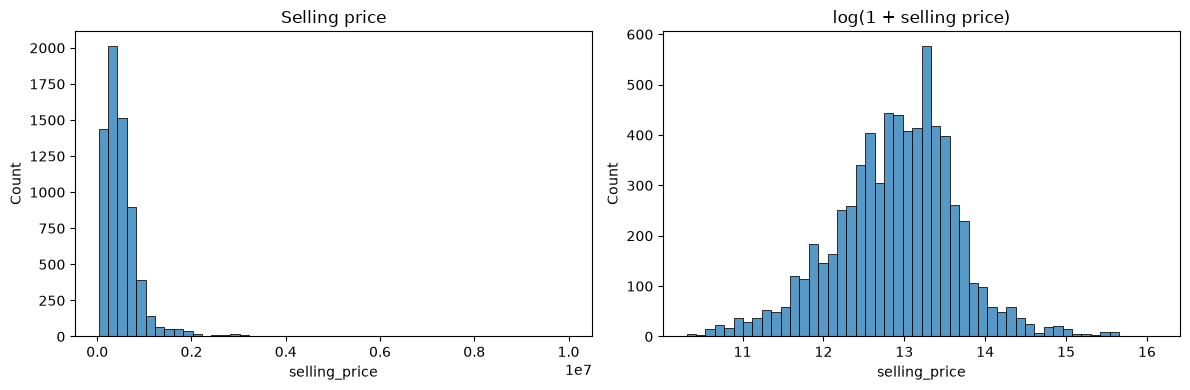

In [20]:
print(df["selling_price"].describe())
print()
print("Skewness:", df["selling_price"].skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["selling_price"], bins=50, ax=axes[0])
axes[0].set_title("Selling price")

sns.histplot(np.log1p(df["selling_price"]), bins=50, ax=axes[1])
axes[1].set_title("log(1 + selling price)")

plt.tight_layout()
plt.show()

count    6718.000000
mean     2013.609110
std         3.900648
min      1994.000000
25%      2011.000000
50%      2014.000000
75%      2017.000000
max      2020.000000
Name: year, dtype: float64



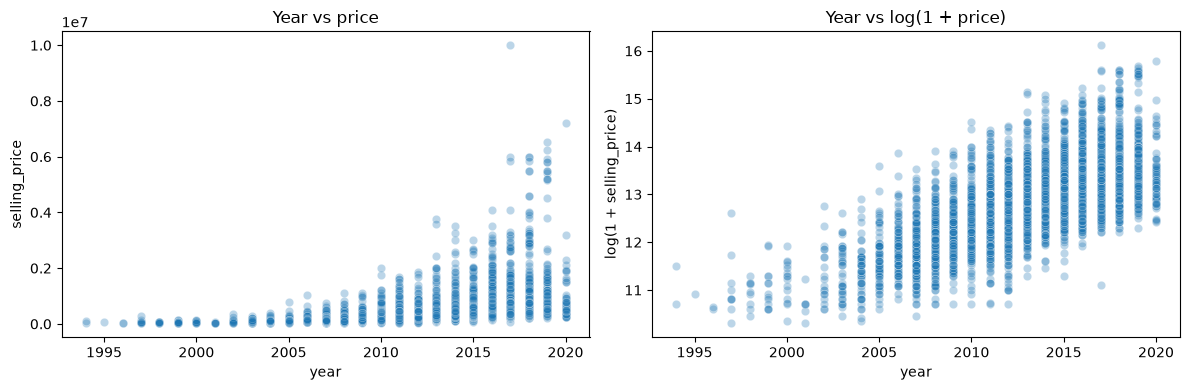

In [21]:
print(df["year"].describe())
print()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(x="year", y="selling_price", data=df, alpha=0.3, ax=axes[0])
axes[0].set_title("Year vs price")

sns.scatterplot(x=df["year"], y=np.log1p(df["selling_price"]), alpha=0.3, ax=axes[1])
axes[1].set_title("Year vs log(1 + price)")
axes[1].set_ylabel("log(1 + selling_price)")

plt.tight_layout()
plt.show()

count    6.718000e+03
mean     7.340230e+04
std      5.869980e+04
min      1.000000e+00
25%      3.800000e+04
50%      6.822150e+04
75%      1.000000e+05
max      2.360457e+06
Name: km_driven, dtype: float64

Skewness: 11.916337643145889


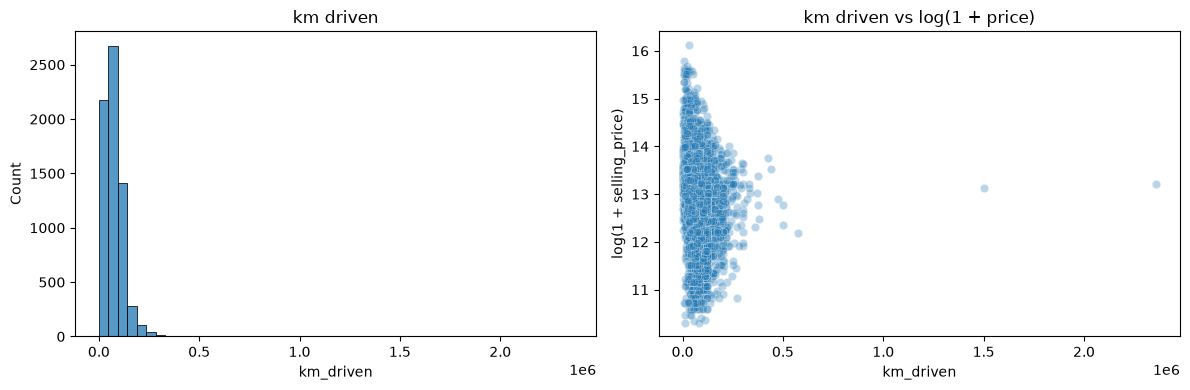

In [22]:
print(df["km_driven"].describe())
print()
print("Skewness:", df["km_driven"].skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["km_driven"], bins=50, ax=axes[0])
axes[0].set_title("km driven")

sns.scatterplot(x=df["km_driven"], y=np.log1p(df["selling_price"]), alpha=0.3, ax=axes[1])
axes[1].set_title("km driven vs log(1 + price)")
axes[1].set_ylabel("log(1 + selling_price)")

plt.tight_layout()
plt.show()

In [23]:
print("km_driven percentiles:")
print(df["km_driven"].quantile([0.90, 0.95, 0.99, 0.999]))
print()

print("Rows with km_driven > 500,000:")
print(df[df["km_driven"] > 500000][["name", "year", "selling_price", "km_driven", "fuel"]])
print()

print("Rows with km_driven < 500:")
print((df["km_driven"] < 500).sum())
print(df[df["km_driven"] < 500][["name", "year", "selling_price", "km_driven"]].head(10))

km_driven percentiles:
0.900    120000.00
0.950    155000.00
0.990    239906.67
0.999    429962.00
Name: km_driven, dtype: float64

Rows with km_driven > 500,000:
                          name  year  selling_price  km_driven    fuel
1595    Mahindra XUV500 W6 2WD  2012         500000    1500000  Diesel
3055      Hyundai i20 Asta 1.2  2007         550000    2360457  Petrol
3077  Maruti Wagon R LXI Minor  2010         194000     577414  Petrol

Rows with km_driven < 500:
1
                                        name  year  selling_price  km_driven
6533  Maruti Eeco 5 STR With AC Plus HTR CNG  2011         209000          1


In [24]:
print("Before:", df.shape)

# 1. Drop the two impossible-km rows
df = df[df["km_driven"] < 1000000].reset_index(drop=True)

# 2. Treat 1 km as unknown
df["km_driven"] = df["km_driven"].replace(1, np.nan)

print("After:", df.shape)
print("Missing km_driven:", df["km_driven"].isnull().sum())
print("Max km_driven:", df["km_driven"].max())
print("Min km_driven:", df["km_driven"].min())

Before: (6718, 13)
After: (6716, 13)
Missing km_driven: 1
Max km_driven: 577414.0
Min km_driven: 1000.0


In [25]:
for col in ["fuel", "seller_type", "transmission", "owner"]:
    print(col)
    print(df.groupby(col)["selling_price"].agg(["count", "median"]).sort_values("count", ascending=False))
    print()

fuel
        count    median
fuel                   
Diesel   3657  525000.0
Petrol   2972  320000.0
CNG        52  327500.0
LPG        35  200000.0

seller_type
                  count    median
seller_type                      
Individual         6023  400000.0
Dealer              666  625000.0
Trustmark Dealer     27  650000.0

transmission
              count    median
transmission                 
Manual         6141  400000.0
Automatic       575  850000.0

owner
                      count     median
owner                                 
First Owner            4175   500000.0
Second Owner           1888   320000.0
Third Owner             493   229999.0
Fourth & Above Owner    155   185000.0
Test Drive Car            5  5923000.0



In [26]:
print(df["owner"].value_counts())
print()
print(df[df["owner"] == "Test Drive Car"][["name", "year", "selling_price", "km_driven", "fuel", "seller_type"]])

owner
First Owner             4175
Second Owner            1888
Third Owner              493
Fourth & Above Owner     155
Test Drive Car             5
Name: count, dtype: int64

                                        name  year  selling_price  km_driven    fuel seller_type
3706  Volkswagen Vento 1.5 TDI Highline BSIV  2019        1350000     5400.0  Diesel      Dealer
4153                  Audi A6 35 TFSI Matrix  2019        6223000     7800.0  Petrol      Dealer
4154                  Audi A6 35 TFSI Matrix  2019        5923000    11500.0  Petrol      Dealer
4155                  Audi A6 35 TFSI Matrix  2019        6523000    23600.0  Petrol      Dealer
5186                          Honda Civic ZX  2019        2000000    24857.0  Petrol      Dealer


In [27]:
print("Before:", df.shape)
df = df[df["owner"] != "Test Drive Car"].reset_index(drop=True)
print("After:", df.shape)
print(df["owner"].value_counts())

Before: (6716, 13)
After: (6711, 13)
owner
First Owner             4175
Second Owner            1888
Third Owner              493
Fourth & Above Owner     155
Name: count, dtype: int64


log_price    1.000000
year         0.709425
max_power    0.653059
engine       0.474176
seats        0.269367
mileage      0.018459
km_driven   -0.224205
Name: log_price, dtype: float64


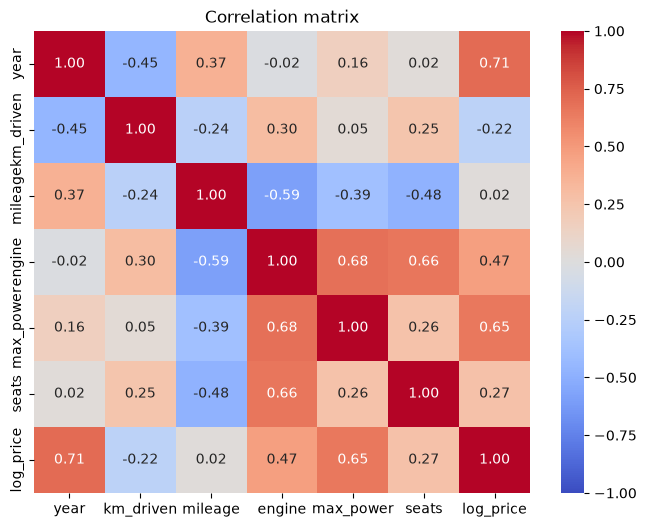

In [28]:
num_cols = ["year", "km_driven", "mileage", "engine", "max_power", "seats"]

corr_df = df[num_cols].copy()
corr_df["log_price"] = np.log1p(df["selling_price"])

corr = corr_df.corr()
print(corr["log_price"].sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

In [29]:
df_clean = df.drop(columns=["name"])
df_clean.to_csv("../data/cleaned_cars.csv", index=False)

print(df_clean.shape)
print(df_clean.columns.tolist())
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

(6711, 12)
['year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'seats', 'brand']
km_driven     1
mileage      15
max_power     1
dtype: int64
